<a href="https://colab.research.google.com/github/VanshikaJain2105/IPL-First-Innings-Score-Prediction/blob/main/IPL_First_Innings_Score_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IPL First Innings Score Prediction

Goal: Given a batting team's current score, wickets, overs and recent performance, predict its final first-innings score.

Dataset: ipl.csv which contains historical IPL deliveries, 2008–2017

**exploring data → cleaning → understanding cricket overs → visualizations → categorical encoding → time-based train/validation/test split → comparing regression models → evaluation → making predictions**

In [ ]:
#Importing Libraries
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42  # Fixed seed makes random model results reproducible

# Loading and understand the data
Each row represents a snapshot during a first innings, rather than a whole match. The total column gives the eventual innings score that we're trying to predict.


**Key fields**:

runs=current runs

wickets=fallen wickets

overs=ball/over position

runs_last_5 and wickets_last_5=recent performance

bat_team/bowl_team=the teams


In [ ]:
df = pd.read_csv("/content/ipl.csv")
print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (76014, 15)


,mid,date,venue,bat_team,bowl_team,batsman,bowler,runs,wickets,overs,runs_last_5,wickets_last_5,striker,non-striker,total
0,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,SC Ganguly,P Kumar,1,0,0.1,1,0,0,0,222
1,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,1,0,0.2,1,0,0,0,222
2,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,2,0,0.2,2,0,0,0,222
3,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,2,0,0.3,2,0,0,0,222
4,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,2,0,0.4,2,0,0,0,222


In [ ]:
# Examine column types, missing values and date coverage
print("Column types:", df.dtypes)

Column types: mid                 int64
date               object
venue              object
bat_team           object
bowl_team          object
batsman            object
bowler             object
runs                int64
wickets             int64
overs             float64
runs_last_5         int64
wickets_last_5      int64
striker             int64
non-striker         int64
total               int64
dtype: object


In [ ]:
print("Missing values:", df.isna().sum())


Missing values: mid               0
date              0
venue             0
bat_team          0
bowl_team         0
batsman           0
bowler            0
runs              0
wickets           0
overs             0
runs_last_5       0
wickets_last_5    0
striker           0
non-striker       0
total             0
dtype: int64


In [ ]:
print("Unique match IDs:", df["mid"].nunique())

Unique match IDs: 617


In [ ]:
print("Dates:", df["date"].min(), "to", df["date"].max())

Dates: 2008-04-18 to 2017-05-21


In [ ]:
#Keep teams with a consistent history in this dataset
consistent_teams = [
    "Chennai Super Kings", "Delhi Daredevils", "Kings XI Punjab",
    "Kolkata Knight Riders", "Mumbai Indians", "Rajasthan Royals",
    "Royal Challengers Bangalore", "Sunrisers Hyderabad"
]

In [ ]:
# Make a copy, so our original data remains unchanged
data = df.loc[
    df["bat_team"].isin(consistent_teams)
    & df["bowl_team"].isin(consistent_teams)
].copy()

In [ ]:
# Convert the date from text to a proper datetime value
data["date"] = pd.to_datetime(data["date"], format="%Y-%m-%d")
print("Original rows:", len(df))
print("Rows after filtering teams:", len(data))

Original rows: 76014
Rows after filtering teams: 53811


# Turn cricket overs into balls bowled


In Cricket 10.3 means 10 full overs and 3 balls = 63 legal balls, not 10.3 decimal overs.

Also, a value like 0.6 in this historical CSV means 6 balls, which is the same match progress as 1.0 overs

Using a continuous balls-bowled count prevents the model from misunderstanding the distance between overs

In [ ]:
# Converting overs into balls
# In cricket, 5.2 overs means 5 overs and 2 balls, not 5.2 decimal overs

def overs_to_balls(overs):
    full_overs = int(overs)
    remaining_balls = round((overs - full_overs) * 10)
    return full_overs * 6 + remaining_balls

data['balls_bowled'] = data['overs'].apply(overs_to_balls)

# Removing the first 5 overs as early predictions can be less reliable
data = data[data['balls_bowled'] >= 30]

data.head()

,mid,date,venue,bat_team,bowl_team,batsman,bowler,runs,wickets,overs,runs_last_5,wickets_last_5,striker,non-striker,total,balls_bowled
31,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,SC Ganguly,P Kumar,60,0,4.6,59,0,40,10,222,30
32,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,Z Khan,61,0,5.1,59,0,41,10,222,31
33,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,SC Ganguly,Z Khan,61,1,5.2,59,1,41,10,222,32
34,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,RT Ponting,Z Khan,61,1,5.3,59,1,41,0,222,33
35,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,RT Ponting,Z Khan,61,1,5.4,59,1,41,0,222,34


# Choose the input features and target
Features (X): information we'd actually know during the innings

Target (y): the final first-innings total (total)

We exclude total from X:  **otherwise the model would receive the answer it is supposed to predict!**

In [ ]:
categorical_features = ["bat_team", "bowl_team"]
numeric_features = [
    "balls_bowled", "runs", "wickets", "runs_last_5", "wickets_last_5"
]
feature_columns = categorical_features + numeric_features
target_column = "total"

# Basic sanity checks on the data.
assert data["wickets"].between(0, 10).all()
assert data["balls_bowled"].between(30, 120).all()
assert (data["total"] >= data["runs"]).all()
print("Predictor columns:", feature_columns)
print("Target:", target_column)

Predictor columns: ['bat_team', 'bowl_team', 'balls_bowled', 'runs', 'wickets', 'runs_last_5', 'wickets_last_5']
Target: total


As always after cleaning we get to the next stage: **(EDA) Exploratory Data Analysis**

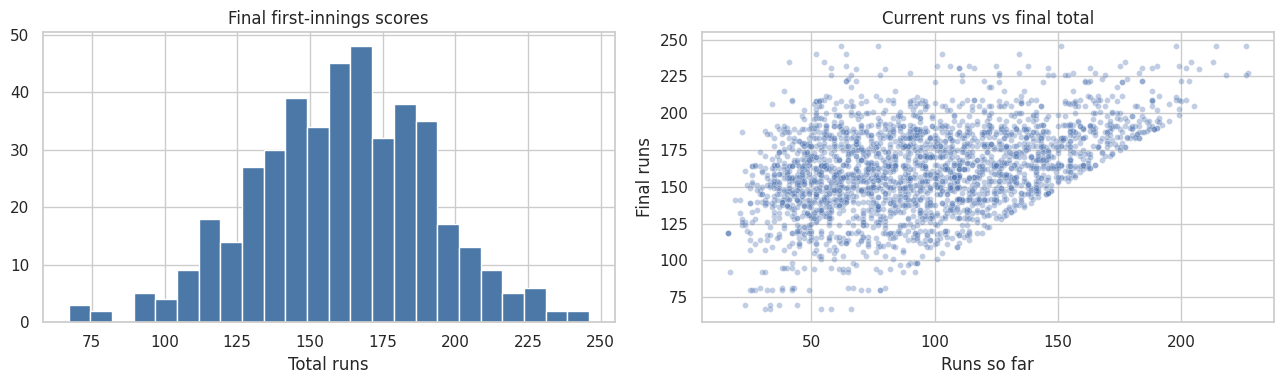

In [ ]:
# Each match ID represents one innings in this CSV
match_summary = (data.sort_values(["mid", "balls_bowled"]).drop_duplicates(subset="mid", keep="last"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(match_summary["total"], bins=24, color="#4C78A8", edgecolor="white")
axes[0].set(title="Final first-innings scores", xlabel="Total runs")

sns.scatterplot(data=data.sample(min(2500, len(data)), random_state=RANDOM_STATE),
                x="runs", y="total", alpha=0.35, s=18, ax=axes[1])
axes[1].set(title="Current runs vs final total", xlabel="Runs so far", ylabel="Final runs")

plt.tight_layout()
plt.show()

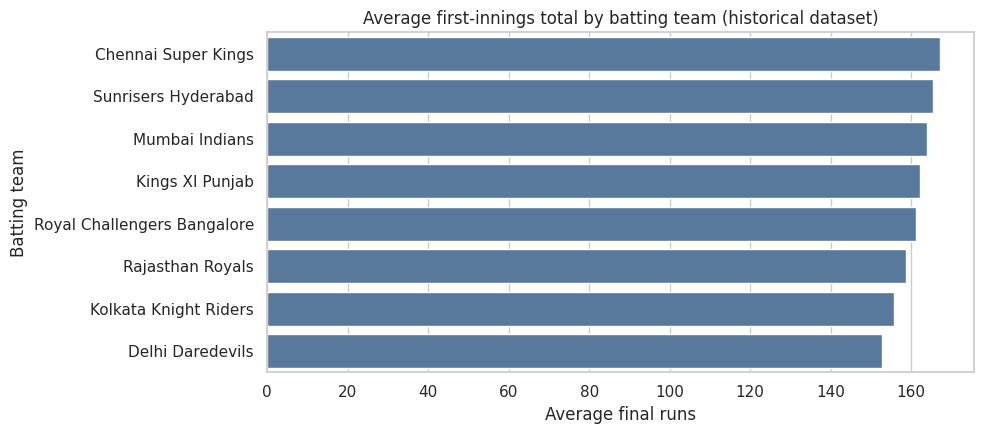

In [ ]:
# Average final first-innings score by batting team (one row per match).
team_averages = (
    match_summary.groupby("bat_team")["total"]
    .mean().sort_values(ascending=False)
)
plt.figure(figsize=(10, 4.5))
sns.barplot(x=team_averages.values, y=team_averages.index, color="#4C78A8")
plt.xlabel("Average final runs")
plt.ylabel("Batting team")
plt.title("Average first-innings total by batting team (historical dataset)")
plt.tight_layout()
plt.show()

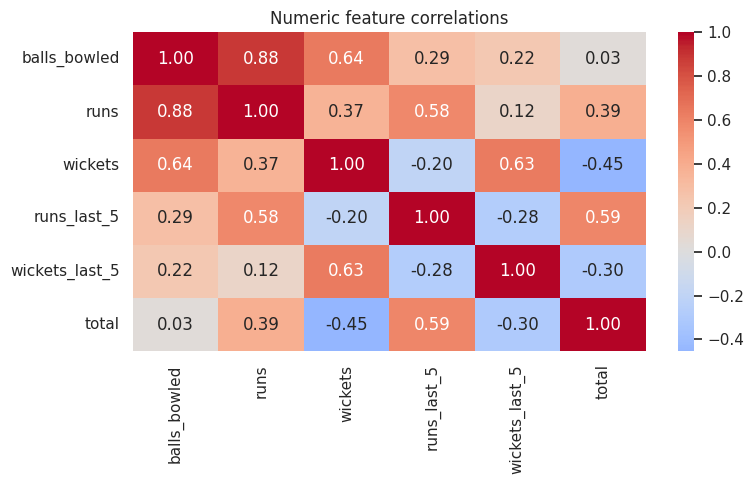

In [ ]:
# Correlation is only meaningful for numeric columns.
heatmap_columns = numeric_features + [target_column]
plt.figure(figsize=(8, 5))
sns.heatmap(data[heatmap_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numeric feature correlations")
plt.tight_layout()
plt.show()

Rows from the same match share the same final target score and a random row split could place balls from the same innings in both train and test, producing overly optimistic evaluation.

We'll train using 2008–2015

choose our model using 2016

and perform the final unbiased evaluation on 2017

In [ ]:
train_df = data.loc[data["date"].dt.year <= 2015].copy()
valid_df = data.loc[data["date"].dt.year == 2016].copy()
test_df  = data.loc[data["date"].dt.year == 2017].copy()

# Confirm matches haven't accidentally appeared in more than one split.
assert set(train_df.mid).isdisjoint(valid_df.mid)
assert set(train_df.mid).isdisjoint(test_df.mid)
assert set(valid_df.mid).isdisjoint(test_df.mid)

X_train, y_train = train_df[feature_columns], train_df[target_column]
X_valid, y_valid = valid_df[feature_columns], valid_df[target_column]
X_test, y_test = test_df[feature_columns], test_df[target_column]

for name, split in [("Train", train_df), ("Validation", valid_df), ("Test", test_df)]:
    print(f"{name:10s}: {len(split):5d} rows, {split.mid.nunique():3d} matches")

Train     : 34840 rows, 376 matches
Validation:  2897 rows,  31 matches
Test      :  2808 rows,  30 matches


Models need numeric inputs, but team names are strings.

**One-hot encoding** converts a team such as Mumbai Indians into a column of 0s and 1s.


A pipeline is useful because the exact same transformations run during training and prediction. This avoids the risk of mixing up manually written columns.


**handle_unknown="ignore"** means an unseen category won't crash the encoder (though predictions for unseen teams may not be reliable)

**StandardScaler** keeps numeric features on comparable scales for linear models.

We fit the preprocessing only on the training data inside each model's pipeline

In [ ]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("teams", OneHotEncoder(handle_unknown="ignore"), categorical_features),
            ("numbers", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]), numeric_features),
        ]
    )


def make_pipeline(regressor):
    """Bundle preprocessing and one regression model together."""
    return Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", regressor),
    ])

print("Reusable preprocessing pipeline created.")

Reusable preprocessing pipeline created.


## Training and compare five regression algorithms

A **regressor** predicts a number (the final number of runs), not a category.

- **Linear Regression:** learns a weighted linear relationship
- **Ridge Regression:** linear regression with regularization
- **Decision Tree:** splits data using if/else-like rules
- **Random Forest:** combines many trees to reduce instability
- **Gradient Boosting:** builds trees sequentially to correct earlier errors

We compare models using **validation** scores. We keep random_state fixed for reproducibility

**Evaluation terms:**
- **MAE:** average absolute error in *runs*. Lower is better
- **RMSE:** penalizes larger mistakes more heavily. Lower is better
- **R²:** how much target variation the model explains; can be negative

In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=20.0),
    "Decision Tree": DecisionTreeRegressor(max_depth=12, min_samples_leaf=5,
                                          random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=80, max_depth=15,
                                            min_samples_leaf=4, n_jobs=-1,
                                            random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=120,
                                                    learning_rate=0.06,
                                                    max_depth=3,
                                                    random_state=RANDOM_STATE),
}

trained_models = {}
validation_rows = []

for name, regressor in models.items():
    pipeline = make_pipeline(regressor)
    pipeline.fit(X_train, y_train)           # Learn using training years only
    prediction = pipeline.predict(X_valid)  # Compare on validation year

    trained_models[name] = pipeline
    validation_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_valid, prediction),
        "RMSE": np.sqrt(mean_squared_error(y_valid, prediction)),
        "R2": r2_score(y_valid, prediction),
    })
    print(f"Finished: {name}")

validation_results = pd.DataFrame(validation_rows).sort_values("MAE").reset_index(drop=True)
display(validation_results.round(3))

Finished: Linear Regression
Finished: Ridge Regression
Finished: Decision Tree
Finished: Random Forest
Finished: Gradient Boosting


,Model,MAE,RMSE,R2
0,Random Forest,12.334,16.569,0.644
1,Linear Regression,12.395,16.380,0.652
2,Ridge Regression,12.397,16.392,0.652
3,Gradient Boosting,12.588,16.639,0.641
4,Decision Tree,14.248,19.074,0.529


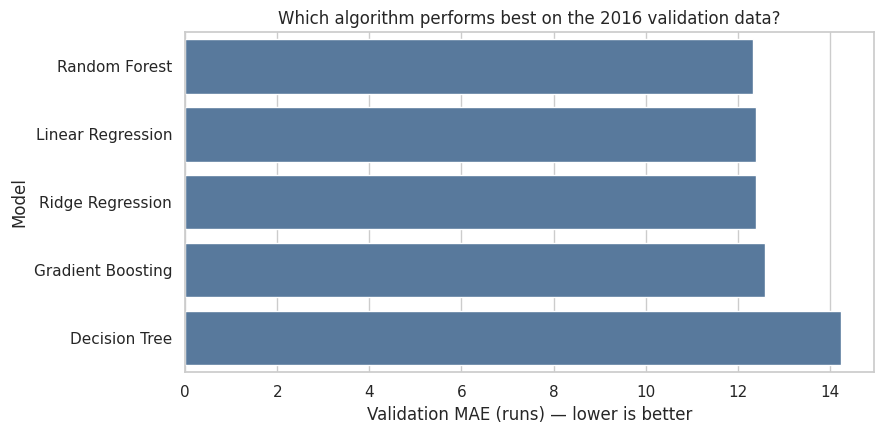

Best model by validation MAE: Random Forest


In [ ]:
# Visual comparison: shorter bars mean lower average prediction error
plt.figure(figsize=(9, 4.5))
sns.barplot(data=validation_results, x="MAE", y="Model", color="#4C78A8")
plt.xlabel("Validation MAE (runs) — lower is better")
plt.title("Which algorithm performs best on the 2016 validation data?")
plt.tight_layout()
plt.show()

best_model_name = validation_results.loc[0, "Model"]
print("Best model by validation MAE:", best_model_name)

## Refit the winning model and test on 2017

After choosing the best algorithm **only from validation results**, we train that algorithm again on the combined **2008–2016** data. Then we evaluate it **once** on 2017

In [ ]:
# Re-create a fresh copy of the selected estimator using sklearn's clone
from sklearn.base import clone

train_valid_df = pd.concat([train_df, valid_df], ignore_index=True)
X_train_valid = train_valid_df[feature_columns]
y_train_valid = train_valid_df[target_column]

best_regressor = clone(models[best_model_name])
final_model = make_pipeline(best_regressor)
final_model.fit(X_train_valid, y_train_valid)

test_predictions = final_model.predict(X_test)
test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)

print("FINAL MODEL:", best_model_name)
print(f"2017 Test MAE : {test_mae:.2f} runs")
print(f"2017 Test RMSE: {test_rmse:.2f} runs")
print(f"2017 Test R²  : {test_r2:.3f}")

FINAL MODEL: Random Forest
2017 Test MAE : 13.35 runs
2017 Test RMSE: 17.84 runs
2017 Test R²  : 0.686


A residual is **actual final score − predicted final score**

Values close to zero are better

A scatterplot also reveals whether the model tends to overestimate or underestimate particular totals

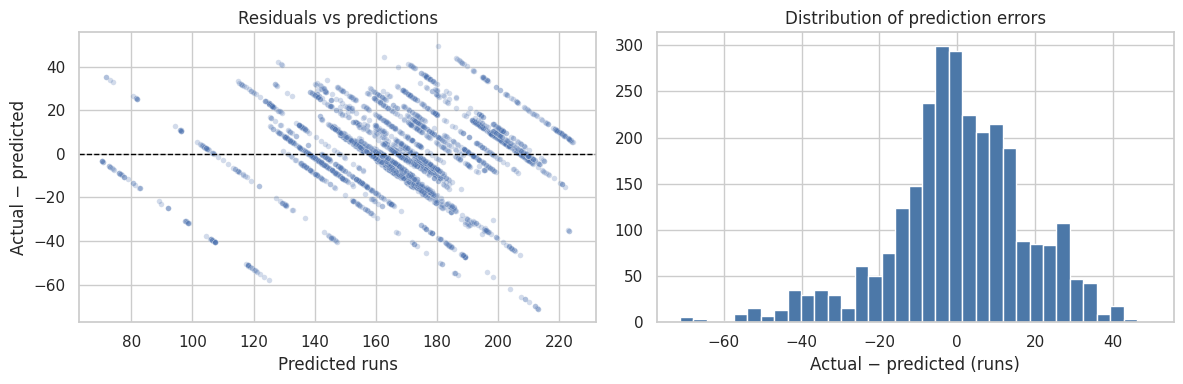

In [ ]:
residuals = y_test.to_numpy() - test_predictions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(x=test_predictions, y=residuals, alpha=0.25, s=16, ax=axes[0])
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set(title="Residuals vs predictions", xlabel="Predicted runs", ylabel="Actual − predicted")
axes[1].hist(residuals, bins=35, color="#4C78A8", edgecolor="white")
axes[1].set(title="Distribution of prediction errors", xlabel="Actual − predicted (runs)")
plt.tight_layout()
plt.show()

In [ ]:
# Group by match and select a representative available snapshot near 60 balls.
midpoint_df = (
    test_df.assign(distance_from_10_overs=(test_df["balls_bowled"] - 60).abs())
           .sort_values(["mid", "distance_from_10_overs", "balls_bowled"])
           .drop_duplicates("mid", keep="first")
)
midpoint_pred = final_model.predict(midpoint_df[feature_columns])
print("2017 matches checked:", midpoint_df.mid.nunique())
print(f"At about 10 overs, match-level MAE: {mean_absolute_error(midpoint_df[target_column], midpoint_pred):.2f} runs")
print(f"At about 10 overs, match-level RMSE: {np.sqrt(mean_squared_error(midpoint_df[target_column], midpoint_pred)):.2f} runs")
display(pd.DataFrame({
    "Batting team": midpoint_df["bat_team"].to_numpy()[:8],
    "Bowling team": midpoint_df["bowl_team"].to_numpy()[:8],
    "Actual": midpoint_df["total"].to_numpy()[:8],
    "Predicted": np.rint(midpoint_pred[:8]).astype(int)
}))

2017 matches checked: 30
At about 10 overs, match-level MAE: 14.47 runs
At about 10 overs, match-level RMSE: 18.52 runs


,Batting team,Bowling team,Actual,Predicted
0,Sunrisers Hyderabad,Royal Challengers Bangalore,207,192
1,Royal Challengers Bangalore,Delhi Daredevils,157,153
2,Kolkata Knight Riders,Mumbai Indians,178,151
3,Royal Challengers Bangalore,Kings XI Punjab,148,135
4,Sunrisers Hyderabad,Mumbai Indians,158,172
5,Kings XI Punjab,Kolkata Knight Riders,170,173
6,Royal Challengers Bangalore,Mumbai Indians,142,184
7,Kolkata Knight Riders,Sunrisers Hyderabad,172,163


The function below takes the current innings situation and returns the **estimated final score**

Input example: CSK batting against Mumbai, score 85/2 after 10.3 overs, with 42 runs and 1 wicket in the previous five overs

We use a DataFrame with feature names, not a hand-assembled NumPy list.

The pipeline handles the encoding automatically.

In [ ]:
def predict_score(batting_team, bowling_team, overs, runs, wickets,
                  runs_last_5, wickets_last_5):
    """Predict final first-innings score using an in-progress innings state."""
    if batting_team not in consistent_teams or bowling_team not in consistent_teams:
        raise ValueError("Use one of the eight historical team labels in consistent_teams.")
    if batting_team == bowling_team:
        raise ValueError("Batting and bowling teams must be different.")
    if not (30 <= overs_to_balls(overs) <= 120):
        raise ValueError("This model expects between 5 and 20 overs of progress.")
    if not (0 <= wickets <= 10 and 0 <= wickets_last_5 <= wickets):
        raise ValueError("Please check the wickets values.")
    if not (0 <= runs_last_5 <= runs):
        raise ValueError("Runs in the last five overs cannot exceed total runs.")

    match_state = pd.DataFrame([{
        "bat_team": batting_team,
        "bowl_team": bowling_team,
        "balls_bowled": overs_to_balls(overs),
        "runs": runs,
        "wickets": wickets,
        "runs_last_5": runs_last_5,
        "wickets_last_5": wickets_last_5,
    }], columns=feature_columns)

    raw_prediction = float(final_model.predict(match_state)[0])
    # A final score cannot be lower than the runs already scored.
    return max(int(round(raw_prediction)), int(runs))

example_score = predict_score(
    batting_team="Chennai Super Kings",
    bowling_team="Mumbai Indians",
    overs=10.3,
    runs=85,
    wickets=2,
    runs_last_5=42,
    wickets_last_5=1,
)
print("Predicted first-innings total:", example_score, "runs")

Predicted first-innings total: 172 runs


We're checking the model's performance in the Model Evaluation section, after training and making predictions

Since IPL Score Prediction is a regression problem, we don't use accuracy_score() like we would for classification. Instead, we calculate:


- **MAE (Mean Absolute Error):** Average difference between actual and predicted scores. Lower is better


- **RMSE (Root Mean Squared Error):** Measures prediction errors, giving larger mistakes more weight. Lower is better


- **R² Score:** Measures how well the model explains variations in the final score. Closer to 1 is better

In [ ]:
# Evaluating the final model on test data

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

test_predictions = final_model.predict(X_test)

mae = mean_absolute_error(y_test, test_predictions)
rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
r2 = r2_score(y_test, test_predictions)

print("Model Evaluation")
print("-------------------------")
print(f"Mean Absolute Error: {mae:.2f} runs")
print(f"Root Mean Squared Error: {rmse:.2f} runs")
print(f"R² Score: {r2:.3f}")

Model Evaluation
-------------------------
Mean Absolute Error: 13.35 runs
Root Mean Squared Error: 17.84 runs
R² Score: 0.686


==========Thankyouuu====================